# Springs Visualization

This notebook visualizes the behavior of different spring types:
- **SigmoidSpring**: Smooth stiffness transition between k1 and k2
- **GaussianSpring**: Repulsive force with Gaussian decay
- **PolynomialSpring**: Polynomial stiffness growth

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Distance range
distance = np.linspace(0.001, 4, 500)

## 1. Sigmoid Spring

Smooth transition between two stiffness values:
- `k(d) = k1 + (k2 - k1) * sigmoid(α(d - threshold))`
- `|F| = k(d) * d`

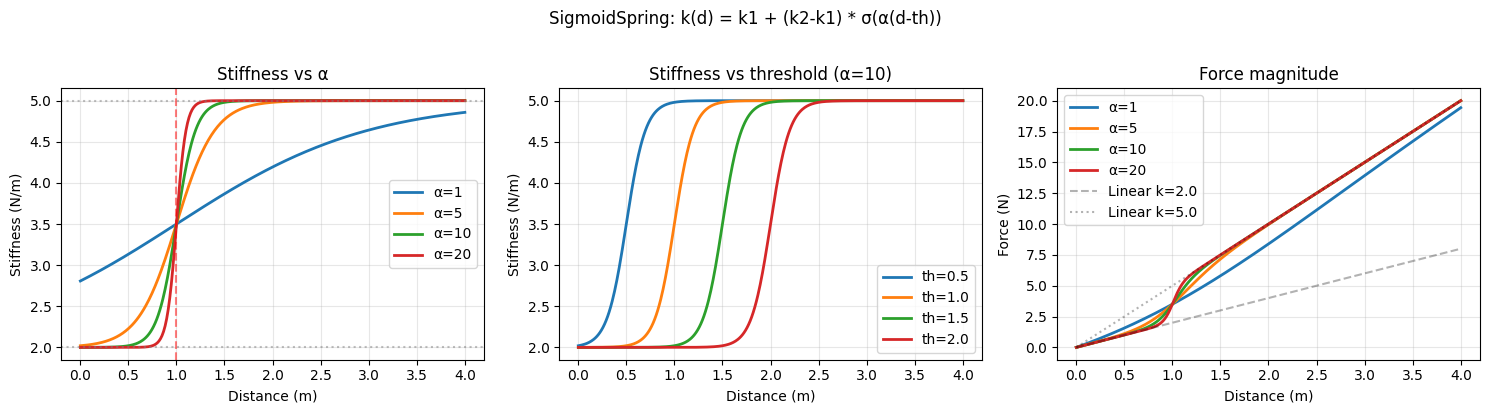

In [2]:
def sigmoid_stiffness(d, k1, k2, threshold, alpha):
    sigmoid = 1.0 / (1.0 + np.exp(-alpha * (d - threshold)))
    return k1 + (k2 - k1) * sigmoid

def sigmoid_force(d, k1, k2, threshold, alpha):
    return sigmoid_stiffness(d, k1, k2, threshold, alpha) * d

# Parameters
k1, k2, threshold = 2.0, 5.0, 1.0

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Effect of alpha
alphas = [1, 5, 10, 20]
for alpha in alphas:
    axes[0].plot(distance, sigmoid_stiffness(distance, k1, k2, threshold, alpha), 
                 label=f'α={alpha}', linewidth=2)
axes[0].axvline(x=threshold, color='r', linestyle='--', alpha=0.5)
axes[0].axhline(y=k1, color='gray', linestyle=':', alpha=0.5)
axes[0].axhline(y=k2, color='gray', linestyle=':', alpha=0.5)
axes[0].set_xlabel('Distance (m)')
axes[0].set_ylabel('Stiffness (N/m)')
axes[0].set_title('Stiffness vs α')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Effect of threshold
thresholds = [0.5, 1.0, 1.5, 2.0]
alpha = 10
for th in thresholds:
    axes[1].plot(distance, sigmoid_stiffness(distance, k1, k2, th, alpha), 
                 label=f'th={th}', linewidth=2)
axes[1].set_xlabel('Distance (m)')
axes[1].set_ylabel('Stiffness (N/m)')
axes[1].set_title('Stiffness vs threshold (α=10)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Force magnitude
for alpha in alphas:
    axes[2].plot(distance, sigmoid_force(distance, k1, k2, threshold, alpha), 
                 label=f'α={alpha}', linewidth=2)
axes[2].plot(distance, k1 * distance, 'k--', alpha=0.3, label=f'Linear k={k1}')
axes[2].plot(distance, k2 * distance, 'k:', alpha=0.3, label=f'Linear k={k2}')
axes[2].set_xlabel('Distance (m)')
axes[2].set_ylabel('Force (N)')
axes[2].set_title('Force magnitude')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('SigmoidSpring: k(d) = k1 + (k2-k1) * σ(α(d-th))', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 2. Gaussian Spring (Repulsive)

Repulsive force that decays with distance from obstacle:
- `decay = exp(-d² / (2σ²))`
- `|F| = A * d * decay` (pushes away from obstacle)

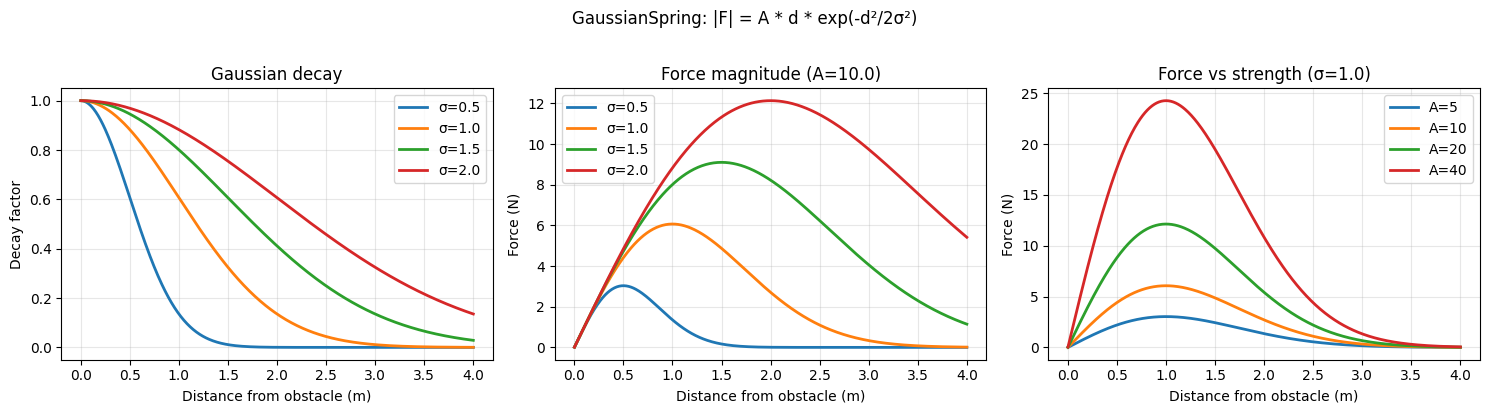

In [3]:
def gaussian_decay(d, sigma):
    return np.exp(-d**2 / (2 * sigma**2))

def gaussian_force(d, strength, sigma):
    return strength * d * gaussian_decay(d, sigma)

# Parameters
strength = 10.0

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Effect of sigma on decay
sigmas = [0.5, 1.0, 1.5, 2.0]
for sigma in sigmas:
    axes[0].plot(distance, gaussian_decay(distance, sigma), 
                 label=f'σ={sigma}', linewidth=2)
axes[0].set_xlabel('Distance from obstacle (m)')
axes[0].set_ylabel('Decay factor')
axes[0].set_title('Gaussian decay')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Effect of sigma on force
for sigma in sigmas:
    axes[1].plot(distance, gaussian_force(distance, strength, sigma), 
                 label=f'σ={sigma}', linewidth=2)
axes[1].set_xlabel('Distance from obstacle (m)')
axes[1].set_ylabel('Force (N)')
axes[1].set_title(f'Force magnitude (A={strength})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Effect of strength
strengths = [5, 10, 20, 40]
sigma = 1.0
for A in strengths:
    axes[2].plot(distance, gaussian_force(distance, A, sigma), 
                 label=f'A={A}', linewidth=2)
axes[2].set_xlabel('Distance from obstacle (m)')
axes[2].set_ylabel('Force (N)')
axes[2].set_title(f'Force vs strength (σ={sigma})')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('GaussianSpring: |F| = A * d * exp(-d²/2σ²)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 3. Polynomial Spring

Stiffness grows polynomially with distance:
- `k(d) = K * (1 + d)^n`
- `|F| = k(d) * d = K * (1 + d)^n * d`

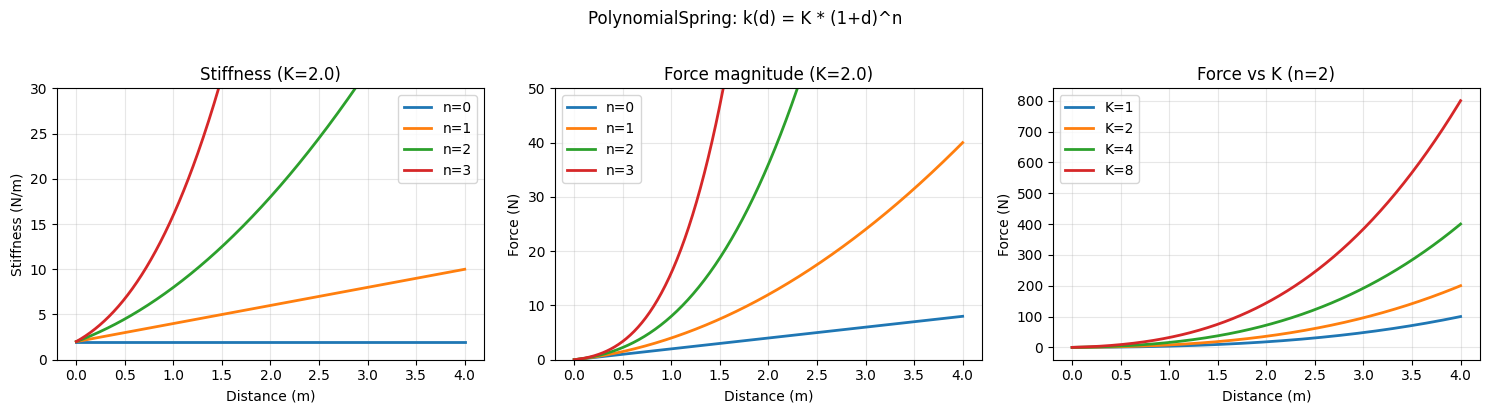

In [4]:
def polynomial_stiffness(d, K, order):
    return K * (1.0 + d)**order

def polynomial_force(d, K, order):
    return polynomial_stiffness(d, K, order) * d

# Parameters
K = 2.0

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Effect of order on stiffness
orders = [0, 1, 2, 3]
for order in orders:
    axes[0].plot(distance, polynomial_stiffness(distance, K, order), 
                 label=f'n={order}', linewidth=2)
axes[0].set_xlabel('Distance (m)')
axes[0].set_ylabel('Stiffness (N/m)')
axes[0].set_title(f'Stiffness (K={K})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(0, 30)

# Effect of order on force
for order in orders:
    axes[1].plot(distance, polynomial_force(distance, K, order), 
                 label=f'n={order}', linewidth=2)
axes[1].set_xlabel('Distance (m)')
axes[1].set_ylabel('Force (N)')
axes[1].set_title(f'Force magnitude (K={K})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0, 50)

# Effect of K
Ks = [1, 2, 4, 8]
order = 2
for K_val in Ks:
    axes[2].plot(distance, polynomial_force(distance, K_val, order), 
                 label=f'K={K_val}', linewidth=2)
axes[2].set_xlabel('Distance (m)')
axes[2].set_ylabel('Force (N)')
axes[2].set_title(f'Force vs K (n={order})')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('PolynomialSpring: k(d) = K * (1+d)^n', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 4. Comparison: All Springs

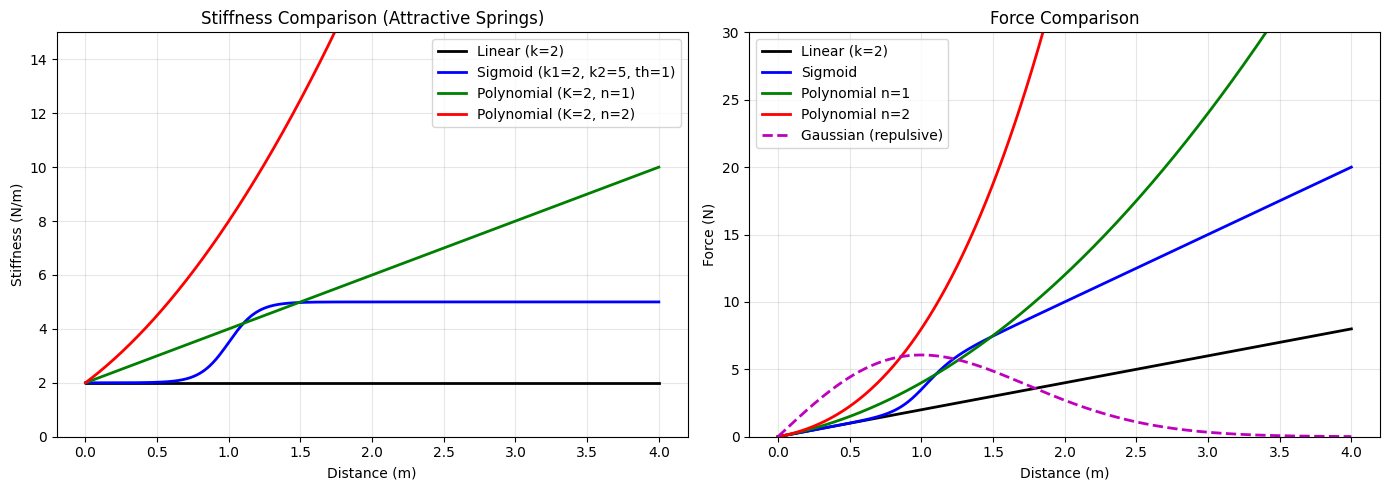

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Attractive springs comparison (stiffness)
ax1 = axes[0]
ax1.plot(distance, np.ones_like(distance) * 2, 'k-', linewidth=2, label='Linear (k=2)')
ax1.plot(distance, sigmoid_stiffness(distance, 2, 5, 1, 10), 'b-', linewidth=2, 
         label='Sigmoid (k1=2, k2=5, th=1)')
ax1.plot(distance, polynomial_stiffness(distance, 2, 1), 'g-', linewidth=2, 
         label='Polynomial (K=2, n=1)')
ax1.plot(distance, polynomial_stiffness(distance, 2, 2), 'r-', linewidth=2, 
         label='Polynomial (K=2, n=2)')
ax1.set_xlabel('Distance (m)')
ax1.set_ylabel('Stiffness (N/m)')
ax1.set_title('Stiffness Comparison (Attractive Springs)')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 15)

# Force comparison
ax2 = axes[1]
ax2.plot(distance, 2 * distance, 'k-', linewidth=2, label='Linear (k=2)')
ax2.plot(distance, sigmoid_force(distance, 2, 5, 1, 10), 'b-', linewidth=2, 
         label='Sigmoid')
ax2.plot(distance, polynomial_force(distance, 2, 1), 'g-', linewidth=2, 
         label='Polynomial n=1')
ax2.plot(distance, polynomial_force(distance, 2, 2), 'r-', linewidth=2, 
         label='Polynomial n=2')
ax2.plot(distance, gaussian_force(distance, 10, 1), 'm--', linewidth=2, 
         label='Gaussian (repulsive)')
ax2.set_xlabel('Distance (m)')
ax2.set_ylabel('Force (N)')
ax2.set_title('Force Comparison')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 30)

plt.tight_layout()
plt.show()